In [ ]:
!pip install lightkurve
!pip install seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 30.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 38.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 85.6 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=fb257d8d3ef1aa3c51933fbcea7abbf9d9465da34f8b2385abb753ee965a41ce
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=5ebdd15551e29c0b3ec0a2c1c1f17844eee1431ef6351c98f1a86bebc14d4111
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightkurve as lk

print("Lightkurve version:", lk.__version__)
print("NumPy version:", np.__version__)


Lightkurve version: 2.6.0
NumPy version: 2.1.3


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [ ]:

search_result = lk.search_lightcurve(
    "Kepler-10",
    mission="Kepler",
    author="Kepler",
    exptime=1800
)

print(search_result)


SearchResult containing 15 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr011904151      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr011904151      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr011904151      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr011904151      0.0
  6 Kepler Quarter 06 2010 Kepler    1800 kplr011904151      0.0
  7 Kepler Quarter 07 2010 Kepler    1800 kplr011904151      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr011904151      0.0
  9 Kepler Quarter 10 2011 Kepler    1800 kplr011904151      0.0
 10 Kepler Quarter 11 2012 Kepler    1800 kplr011904151      0.0
 11 Kepler Quarter 13 2012 Kepler    1800 kplr0

## Why Kepler-10?
- It is a known planetary system.
- It provides a useful astronomical example.
- It allows us to inspect real stellar observations before building our own detector.

In [ ]:

# Convert search results into a table
results_table = search_result.table.to_pandas()

display(results_table.head(10))
print("Total available observations:", len(results_table))


,intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,...,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
0,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,77760,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 00,0,2009,1
1,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,192960,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 01,1,2009,1
2,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,466560,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 02,2,2009,1
3,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,466560,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 03,3,2009,1
4,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,132480,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 04,4,2010,1
5,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,492480,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 05,5,2010,1
6,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,469440,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 06,6,2010,1
7,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,466560,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 07,7,2010,1
8,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,506880,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 09,8,2011,1
9,science,Kepler,Kepler,Kepler,Kepler,KEPLER,OPTICAL,kplr011904151,NaN,kplr011904151_lc_Q111111110111011101,...,486720,582316,PUBLIC,2,KEPLER,Kepler,Kepler Quarter 10,9,2011,1


Total available observations: 15


In [ ]:

# Download one available product for initial investigation
lc = search_result[0].download()

print(lc)
print("Quarter:", getattr(lc, "quarter", "Not available"))
print("Flux origin:", getattr(lc, "flux_origin", "Not available"))


       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  5.0146684e+05 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  5.0141212e+05 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  5.0140281e+05 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  5.0135972e+05 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  5.0144759e+05 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  5.0142422e+05 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  5.0134612e+05 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  5.0136928e+05 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  5.0140212e+05 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  5.0152938e+05 ... -4.6389936e-03 -7.1408441e-03
130.08192158433667  5.0157003e+05 ... -4.6909074

In [ ]:

print("Number of observations:", len(lc))

print("Time range:")
print(np.nanmin(lc.time.value))
print(np.nanmax(lc.time.value))

print("Flux statistics:")
print(pd.Series(np.asarray(lc.flux.value, dtype=np.float64)).describe())


print("Missing flux observations:")
# print(np.isnan(lc.flux.value).sum())
clean_lc = lc.remove_nans()

missing_count = len(lc) - len(clean_lc)

print("Original observations:", len(lc))
print("Valid observations:", len(clean_lc))
print("Missing observations:", missing_count)

Number of observations: 473
Time range:
120.5391465105713
130.24539527622983
Flux statistics:
count       469.000000
mean     501594.678038
std          80.678880
min      501346.125000
25%      501533.718750
50%      501600.218750
75%      501659.093750
max      501746.750000
dtype: float64
Missing flux observations:
Original observations: 473
Valid observations: 469
Missing observations: 4


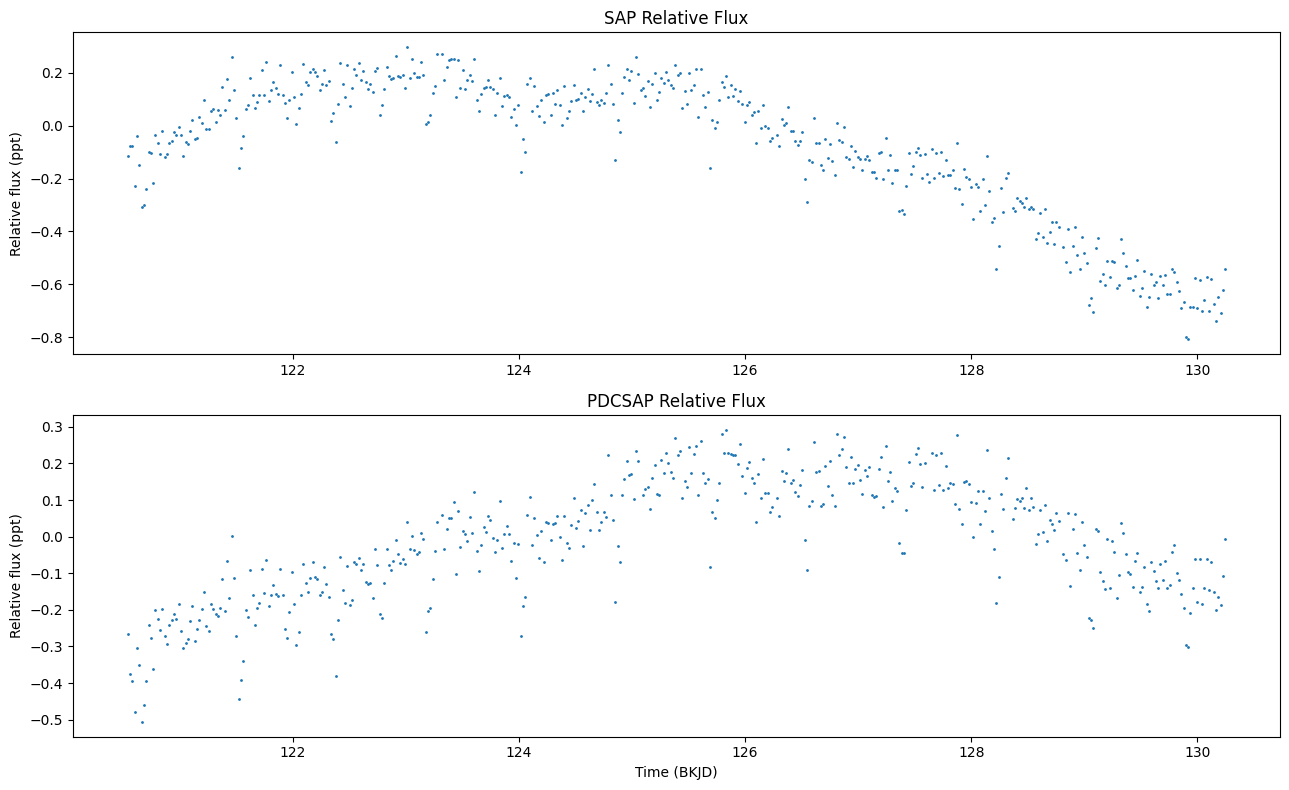

In [ ]:

# Compare relative flux variations in parts per thousand

sap = np.ma.asarray(lc.sap_flux.value)
pdcsap = np.ma.asarray(lc.pdcsap_flux.value)

sap_median = np.ma.median(sap)
pdcsap_median = np.ma.median(pdcsap)

sap_relative = 1000 * (sap / sap_median - 1)
pdcsap_relative = 1000 * (pdcsap / pdcsap_median - 1)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(
    lc.time.value, sap_relative,
    ".", markersize=2
)
axes[0].set_title("SAP Relative Flux")
axes[0].set_ylabel("Relative flux (ppt)")

axes[1].plot(
    lc.time.value, pdcsap_relative,
    ".", markersize=2
)
axes[1].set_title("PDCSAP Relative Flux")
axes[1].set_ylabel("Relative flux (ppt)")
axes[1].set_xlabel("Time (BKJD)")

plt.tight_layout()
plt.show()


After removing missing values: 469
Missing/masked observations: 4


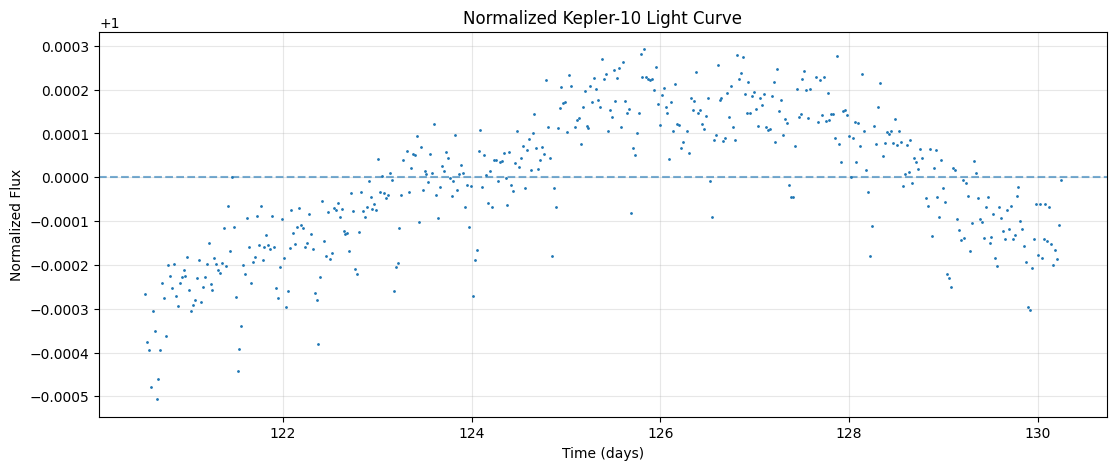

In [ ]:

clean_lc = lc.remove_nans()

normalized_lc = clean_lc.normalize()

plt.figure(figsize=(13, 5))

plt.plot(
    normalized_lc.time.value,
    normalized_lc.flux.value,
    ".",
    markersize=2
)

print("After removing missing values:", len(clean_lc))

missing_count = len(lc) - len(clean_lc)

print("Missing/masked observations:", missing_count)

plt.axhline(1.0, linestyle="--", alpha=0.6)

plt.xlabel("Time (days)")
plt.ylabel("Normalized Flux")
plt.title("Normalized Kepler-10 Light Curve")
plt.grid(alpha=0.3)
plt.show()


NORMALIZED FLUX STATISTICS
-----------------------------------
Mean: 0.99998891
Median: 1.00000000
Standard Deviation: 0.00016067
Minimum: 0.99949342
Maximum: 1.00029218
Range: 0.00079876


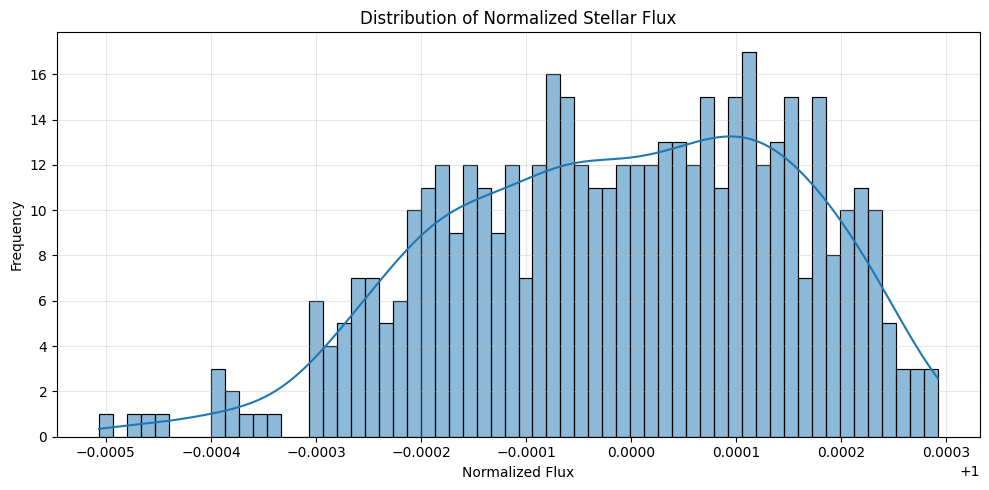

In [ ]:
flux = np.ma.asarray(normalized_lc.flux.value).compressed()
flux = flux[np.isfinite(flux)]

statistics = {
    "Mean": np.mean(flux),
    "Median": np.median(flux),
    "Standard Deviation": np.std(flux),
    "Minimum": np.min(flux),
    "Maximum": np.max(flux),
    "Range": np.ptp(flux)
}

print("NORMALIZED FLUX STATISTICS")
print("-" * 35)

for name, value in statistics.items():
    print(f"{name}: {value:.8f}")

plt.figure(figsize=(10, 5))
sns.histplot(flux, bins=60, kde=True)
plt.xlabel("Normalized Flux")
plt.ylabel("Frequency")
plt.title("Distribution of Normalized Stellar Flux")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Median cadence: 0.020434210422536125
Maximum time gap: 0.06130261759244604
Minimum time gap: 0.020434098951227497


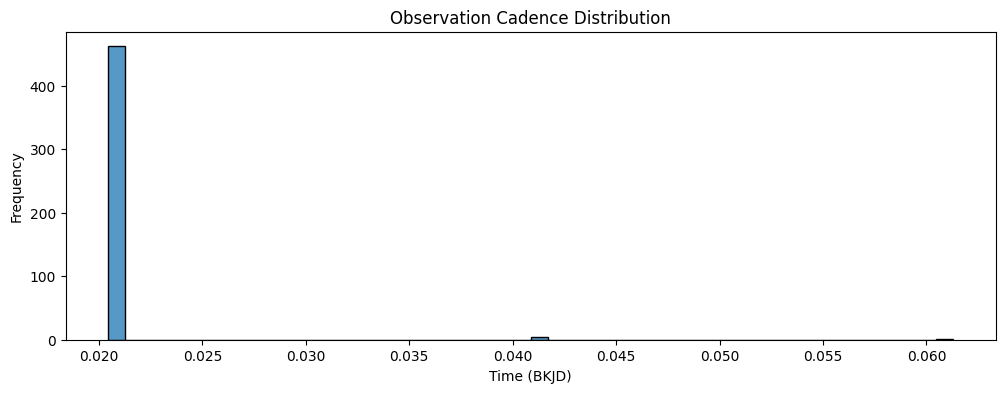

In [ ]:

time = clean_lc.time.value

time_difference = np.diff(time)

print("Median cadence:", np.median(time_difference))
print("Maximum time gap:", np.max(time_difference))
print("Minimum time gap:", np.min(time_difference))

plt.figure(figsize=(12, 4))

sns.histplot(time_difference, bins=50)

plt.xlabel("Time (BKJD)")
plt.ylabel("Frequency")
plt.title("Observation Cadence Distribution")
plt.show()


## Scientific Observations

1. The Kepler-10 Quarter 00 dataset contains 473 observations.
2. Four observations contain missing or masked flux values.
3. The cleaned dataset contains 469 valid observations.
4. The median observation cadence is approximately 29.4 minutes.
5. SAP and PDCSAP show different instrumental and systematic trends.
6. Normalization rescales the flux around unity but does not remove
   every long-term trend.
7. Additional quarters and multiple stellar targets will be needed
   for robust exoplanet detection and model evaluation.

# Phase 3 — Astronomical signal processing and transit detection

### Step 1: Estimate the baseline and flatten the light curve.

In [ ]:
# Estimate and remove long-term variations

flat_lc, trend_lc = normalized_lc.flatten(
    window_length=101,
    polyorder=2,
    return_trend=True
)

print("Original observations:", len(normalized_lc))
print("Flattened observations:", len(flat_lc))

Original observations: 469
Flattened observations: 469


### Step 2: Compare the original and estimated baseline.

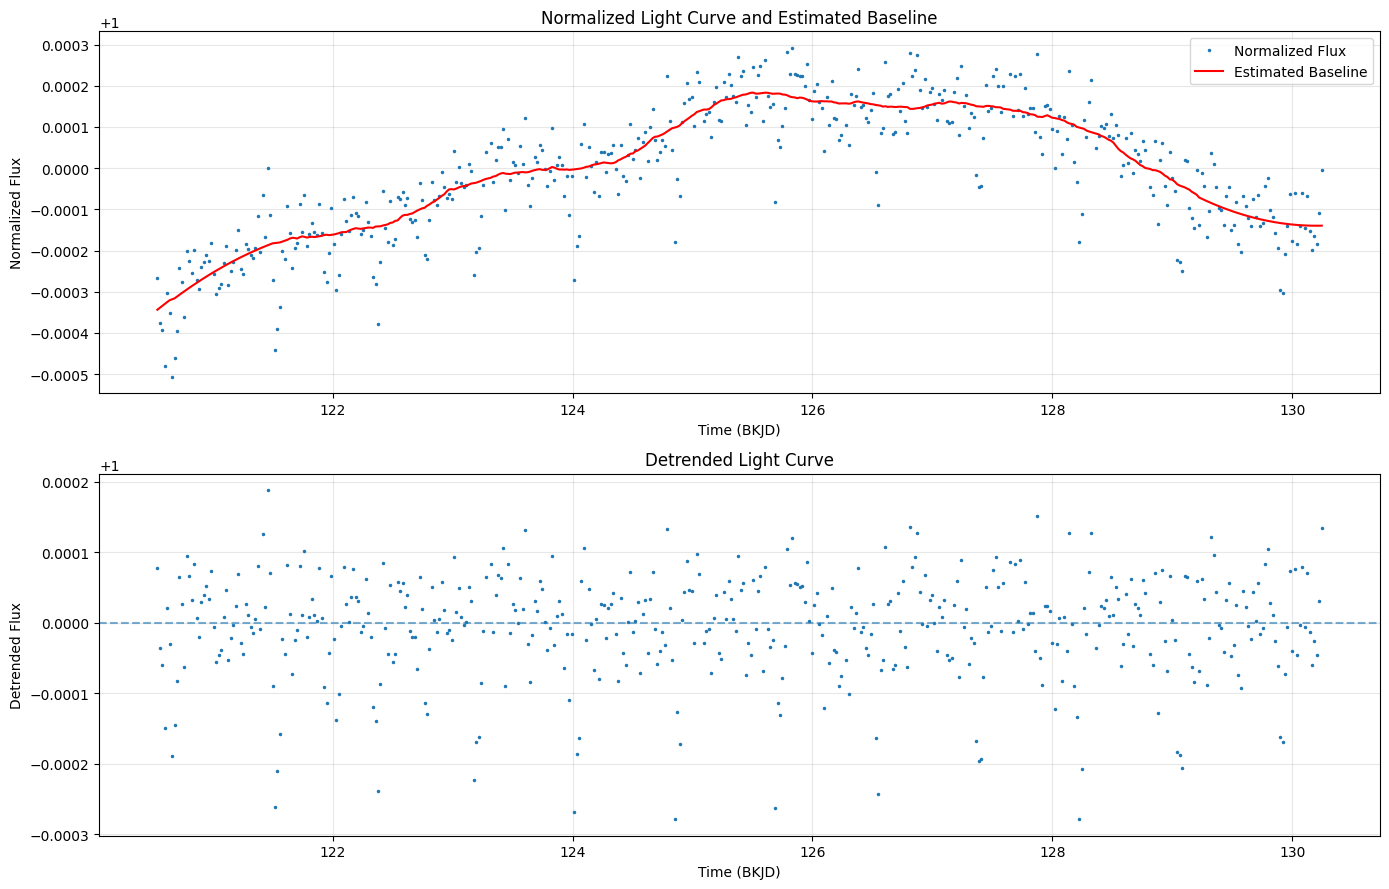

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(
    normalized_lc.time.value,
    normalized_lc.flux.value,
    ".",
    markersize=3,
    label="Normalized Flux"
)

axes[0].plot(
    trend_lc.time.value,
    trend_lc.flux.value,
    color="red",
    label="Estimated Baseline"
)

axes[0].set_title("Normalized Light Curve and Estimated Baseline")
axes[0].set_ylabel("Normalized Flux")
axes[0].set_xlabel("Time (BKJD)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    flat_lc.time.value,
    flat_lc.flux.value,
    ".",
    markersize=3
)

axes[1].axhline(1.0, linestyle="--", alpha=0.6)
axes[1].set_title("Detrended Light Curve")
axes[1].set_ylabel("Detrended Flux")
axes[1].set_xlabel("Time (BKJD)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Step 3: Compare different window lengths.

##### Do not assume that 101 is the best setting. Test several values:

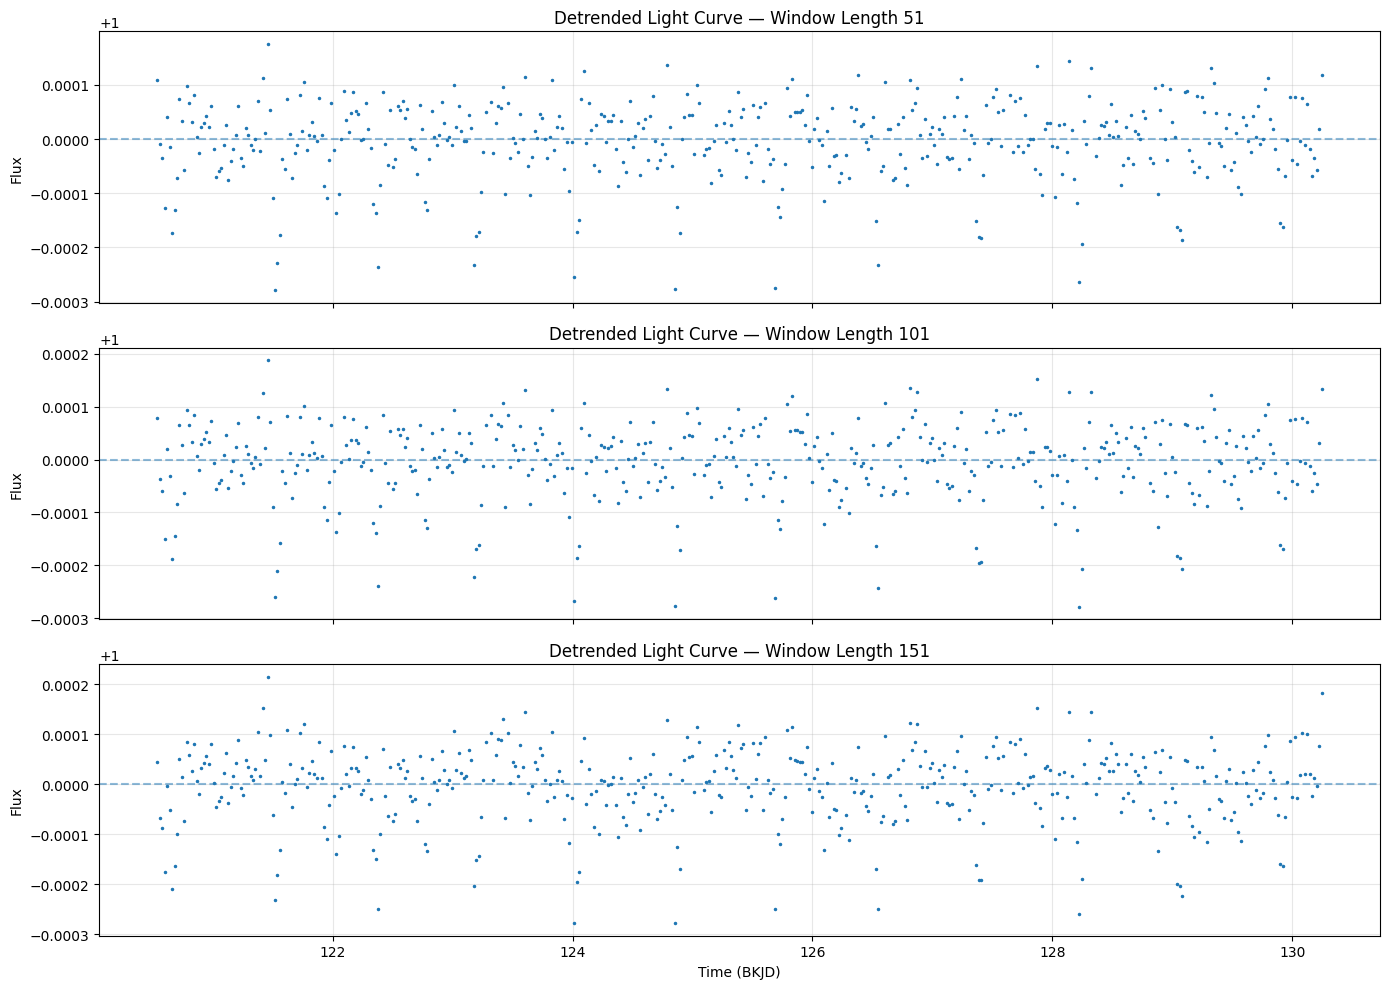

In [ ]:
window_lengths = [51, 101, 151]

fig, axes = plt.subplots(
    len(window_lengths), 1,
    figsize=(14, 10),
    sharex=True
)

for ax, window in zip(axes, window_lengths):

    flattened = normalized_lc.flatten(
        window_length=window,
        polyorder=2
    )

    ax.plot(
        flattened.time.value,
        flattened.flux.value,
        ".",
        markersize=3
    )

    ax.axhline(1.0, linestyle="--", alpha=0.5)
    ax.set_title(f"Detrended Light Curve — Window Length {window}")
    ax.set_ylabel("Flux")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (BKJD)")
plt.tight_layout()
plt.show()

In [ ]:
window_lengths = [51, 101, 151]

results = []

for window in window_lengths:

    flattened = normalized_lc.flatten(
        window_length=window,
        polyorder=2
    )

    flux = np.ma.asarray(flattened.flux.value).compressed()
    flux = flux[np.isfinite(flux)]

    results.append({
        "Window Length": window,
        "Flux Standard Deviation": np.std(flux),
        "Flux Range": np.ptp(flux)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Window Length,Flux Standard Deviation,Flux Range
0,51,0.000074,0.000456
1,101,0.000074,0.000467
2,151,0.000077,0.000494


# 4. Additional scientific experiment — Transit preservation

### Experiment: Can detrending preserve a planetary transit?

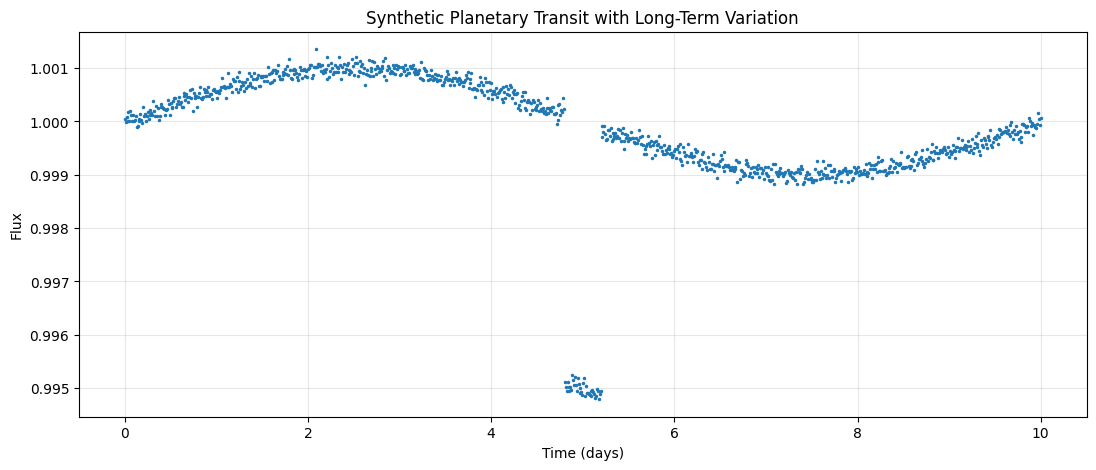

In [ ]:
# Create synthetic light curve

time = np.linspace(0, 10, 1000)

baseline = 1 + 0.001 * np.sin(2 * np.pi * time / 10)

# Simulate a planetary transit
transit = np.ones(len(time))

transit_mask = (time > 4.8) & (time < 5.2)

transit[transit_mask] = 0.995

# Add small observational noise
np.random.seed(42)

noise = np.random.normal(0, 0.0001, len(time))

observed_flux = baseline * transit + noise

synthetic_lc = lk.LightCurve(
    time=time,
    flux=observed_flux
)

plt.figure(figsize=(13, 5))

plt.plot(time, observed_flux, ".", markersize=3)

plt.xlabel("Time (days)")
plt.ylabel("Flux")
plt.title("Synthetic Planetary Transit with Long-Term Variation")

plt.grid(alpha=0.3)
plt.show()

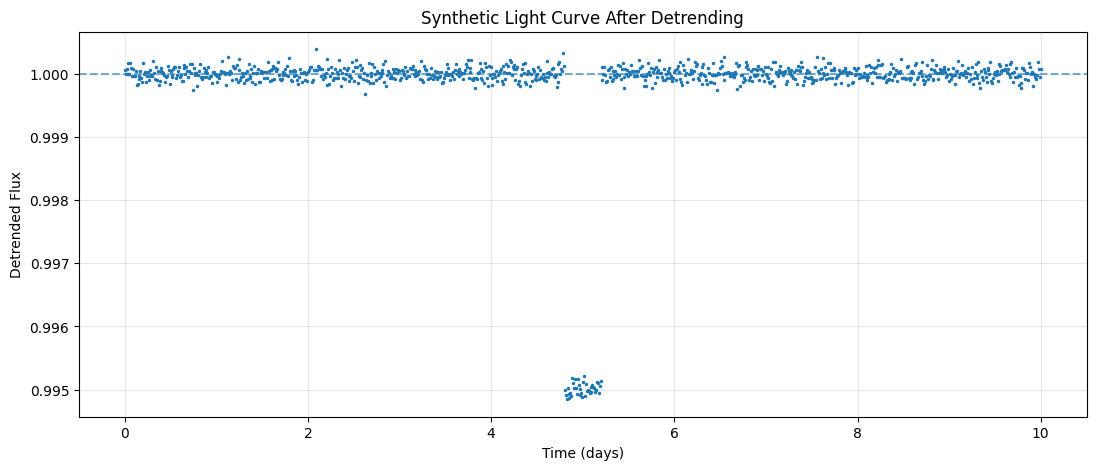

In [ ]:
# Now apply detrending:
synthetic_flat = synthetic_lc.flatten(
    window_length=101,
    polyorder=2
)

plt.figure(figsize=(13, 5))

plt.plot(
    synthetic_flat.time.value,
    synthetic_flat.flux.value,
    ".",
    markersize=3
)

plt.axhline(1.0, linestyle="--", alpha=0.6)

plt.xlabel("Time (days)")
plt.ylabel("Detrended Flux")
plt.title("Synthetic Light Curve After Detrending")

plt.grid(alpha=0.3)
plt.show()

### Bls implimentation

In [ ]:
import astropy.units as u
from astropy.timeseries import BoxLeastSquares

time = np.asarray(flat_lc.time.value)

flux = np.ma.asarray(
    flat_lc.flux.value
).filled(np.nan)

flux_err = np.ma.asarray(
    flat_lc.flux_err.value
).filled(np.nan)

# Keep only valid observations
valid = (
    np.isfinite(time) &
    np.isfinite(flux) &
    np.isfinite(flux_err) &
    (flux_err > 0)
)

time = time[valid]
flux = flux[valid]
flux_err = flux_err[valid]

# Sort all arrays using the same order
sort_index = np.argsort(time)

time = time[sort_index]
flux = flux[sort_index]
flux_err = flux_err[sort_index]

print("Valid observations:", len(time))
print("Time baseline:", time.max() - time.min())
print("Median flux uncertainty:", np.median(flux_err))

# Initialize BLS with uncertainties
bls = BoxLeastSquares(
    time * u.day,
    flux,
    dy=flux_err
)

durations = np.array([1, 2, 3, 4, 5]) * u.hour

periodogram = bls.autopower(
    durations,
    minimum_period=0.5 * u.day,
    maximum_period=4.0 * u.day
)

Valid observations: 469
Time baseline: 9.706248765658529
Median flux uncertainty: 4.133967327131923e-05


In [ ]:
# Find the strongest BLS candidate FIRST

best_index = np.argmax(periodogram.power)

best_period = periodogram.period[best_index]
best_duration = periodogram.duration[best_index]
best_transit_time = periodogram.transit_time[best_index]

print("Best candidate period:", best_period)
print("Transit duration:", best_duration)
print("Transit epoch:", best_transit_time)
print("Maximum BLS power:", periodogram.power[best_index])

# Calculate statistics AFTER defining the candidate

stats = bls.compute_stats(
    best_period,
    best_duration,
    best_transit_time
)

print("\nBLS Candidate Statistics")
print("-" * 40)

for key, value in stats.items():
    print(f"{key}: {value}")

Best candidate period: 0.8355331789160573 d
Transit duration: 0.08333333333333333 d
Transit epoch: 120.7016465105713 d
Maximum BLS power: 330.30645776023863

BLS Candidate Statistics
----------------------------------------
transit_times: [120.70164651 121.53717969 122.37271287 123.20824605 124.04377923
 124.87931241 125.71484558 126.55037876 127.38591194 128.22144512
 129.0569783  129.89251148] d
per_transit_count: [4 4 4 4 4 4 4 4 4 4 4 4]
per_transit_log_likelihood: [ 7.59822086 40.55159589 28.35961236 33.24058976 26.03502488 27.26196899
 28.39110187 23.07126033 32.73159698 39.64263263 29.85095368 13.57189952]
depth: (np.float64(0.0001532631521162786), np.float64(6.293912874595828e-06))
depth_phased: (np.float64(1.4673335870130089e-05), np.float64(6.584185333585052e-06))
depth_half: (np.float64(8.781016685921461e-05), np.float64(4.805030675754516e-06))
depth_odd: (np.float64(0.00015897685793297978), np.float64(8.673040461673574e-06))
depth_even: (np.float64(0.00014755763273677225), 

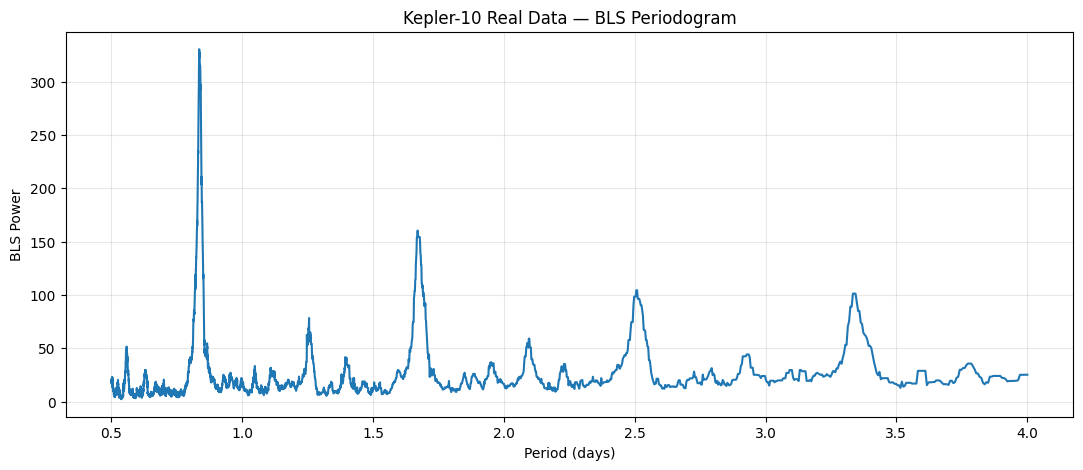

In [ ]:
plt.figure(figsize=(13, 5))

plt.plot(
    periodogram.period.to_value(u.day),
    periodogram.power
)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("Kepler-10 Real Data — BLS Periodogram")

plt.grid(alpha=0.3)
plt.show()

In [ ]:

# ==========================================
# Transit Depth Preservation Analysis
# ==========================================

# 1. Get synthetic original light curve
synthetic_time = np.asarray(synthetic_lc.time.value)
original_flux = np.asarray(synthetic_lc.flux.value)

# Define transit region using synthetic time
original_transit_mask = (
    (synthetic_time > 4.8) &
    (synthetic_time < 5.2)
)

# Define out-of-transit region
original_out_mask = synthetic_time < 4.5

# Calculate original transit depth
original_out = np.nanmedian(original_flux[original_out_mask])
original_in = np.nanmedian(original_flux[original_transit_mask])

original_depth = original_out - original_in


# 2. Get detrended synthetic light curve
flat_time = np.asarray(synthetic_flat.time.value)
flat_flux = np.asarray(synthetic_flat.flux.value)

# Create masks using the detrended light curve's own time array
flat_transit_mask = (
    (flat_time > 4.8) &
    (flat_time < 5.2)
)

flat_out_mask = flat_time < 4.5

# Calculate detrended transit depth
flat_out = np.nanmedian(flat_flux[flat_out_mask])
flat_in = np.nanmedian(flat_flux[flat_transit_mask])

detrended_depth = flat_out - flat_in


# 3. Calculate transit depth preservation
if np.isclose(original_depth, 0):
    raise ValueError("Original transit depth is zero.")

preservation = (detrended_depth / original_depth) * 100


# 4. Display results
print("Original transit depth:", original_depth)
print("Detrended transit depth:", detrended_depth)
print("Transit depth preservation:", preservation, "%")

print("\nArray lengths:")
print("Original time:", len(synthetic_time))
print("Original flux:", len(original_flux))
print("Flattened time:", len(flat_time))
print("Flattened flux:", len(flat_flux))


Original transit depth: 0.005813761399860673
Detrended transit depth: 0.004998590621975163
Transit depth preservation: 85.97859936417332 %

Array lengths:
Original time: 1000
Original flux: 1000
Flattened time: 1000
Flattened flux: 1000


## Phase 4 — Phase folding and transit validation

You have found a candidate period. Now we need to determine whether the observations actually form a repeated transit pattern.
Lesson 4.1 — What is phase folding?
Imagine a planet orbiting its star every 0.8355 days.

The transit repeats after approximately one orbital period.

Instead of plotting all observations against absolute time, phase folding maps observations from different orbital cycles onto a single orbital cycle.

The phase is:
\[
\phi =
\left[
\frac{t-T_0}{P}+\frac{1}{2}
\right]\bmod 1-\frac{1}{2}
\]

Where:
- \(t\) = observation time.
- \(T_0\) = reference transit epoch.
- \(P\) = orbital period.
- \(\phi\) = orbital phase.
A genuine repeating transit should produce a consistent brightness dip around phase zero.

#### 4.2 — Generate your phase-folded real Kepler-10 light curve

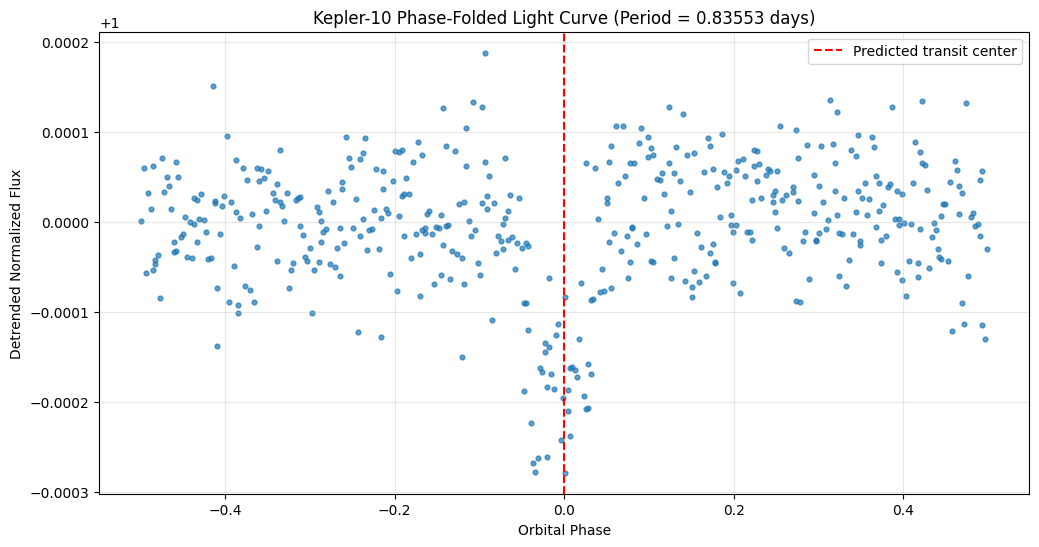

In [ ]:
# Convert BLS results into numerical days

period_value = best_period.to_value(u.day)

epoch_value = best_transit_time.to_value(u.day)

# Calculate orbital phase
phase = (
    (time - epoch_value) / period_value + 0.5
) % 1 - 0.5

# Sort observations by phase
sort_index = np.argsort(phase)

phase_sorted = phase[sort_index]
flux_sorted = flux[sort_index]

# Plot phase-folded light curve
plt.figure(figsize=(12, 6))

plt.scatter(
    phase_sorted,
    flux_sorted,
    s=12,
    alpha=0.7
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Predicted transit center"
)

plt.xlabel("Orbital Phase")
plt.ylabel("Detrended Normalized Flux")

plt.title(
    f"Kepler-10 Phase-Folded Light Curve "
    f"(Period = {period_value:.5f} days)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 4.3 — Zoom into the transit

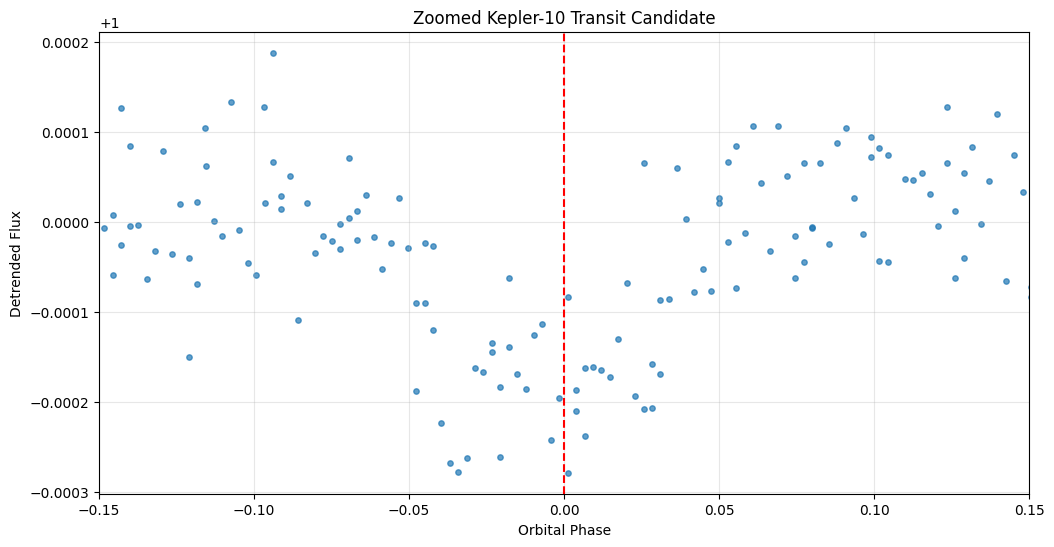

In [ ]:
plt.figure(figsize=(12, 6))

plt.scatter(
    phase_sorted,
    flux_sorted,
    s=15,
    alpha=0.7
)

plt.xlim(-0.15, 0.15)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Orbital Phase")
plt.ylabel("Detrended Flux")

plt.title("Zoomed Kepler-10 Transit Candidate")

plt.grid(alpha=0.3)
plt.show()

#### 4.4 — Individual transit consistency

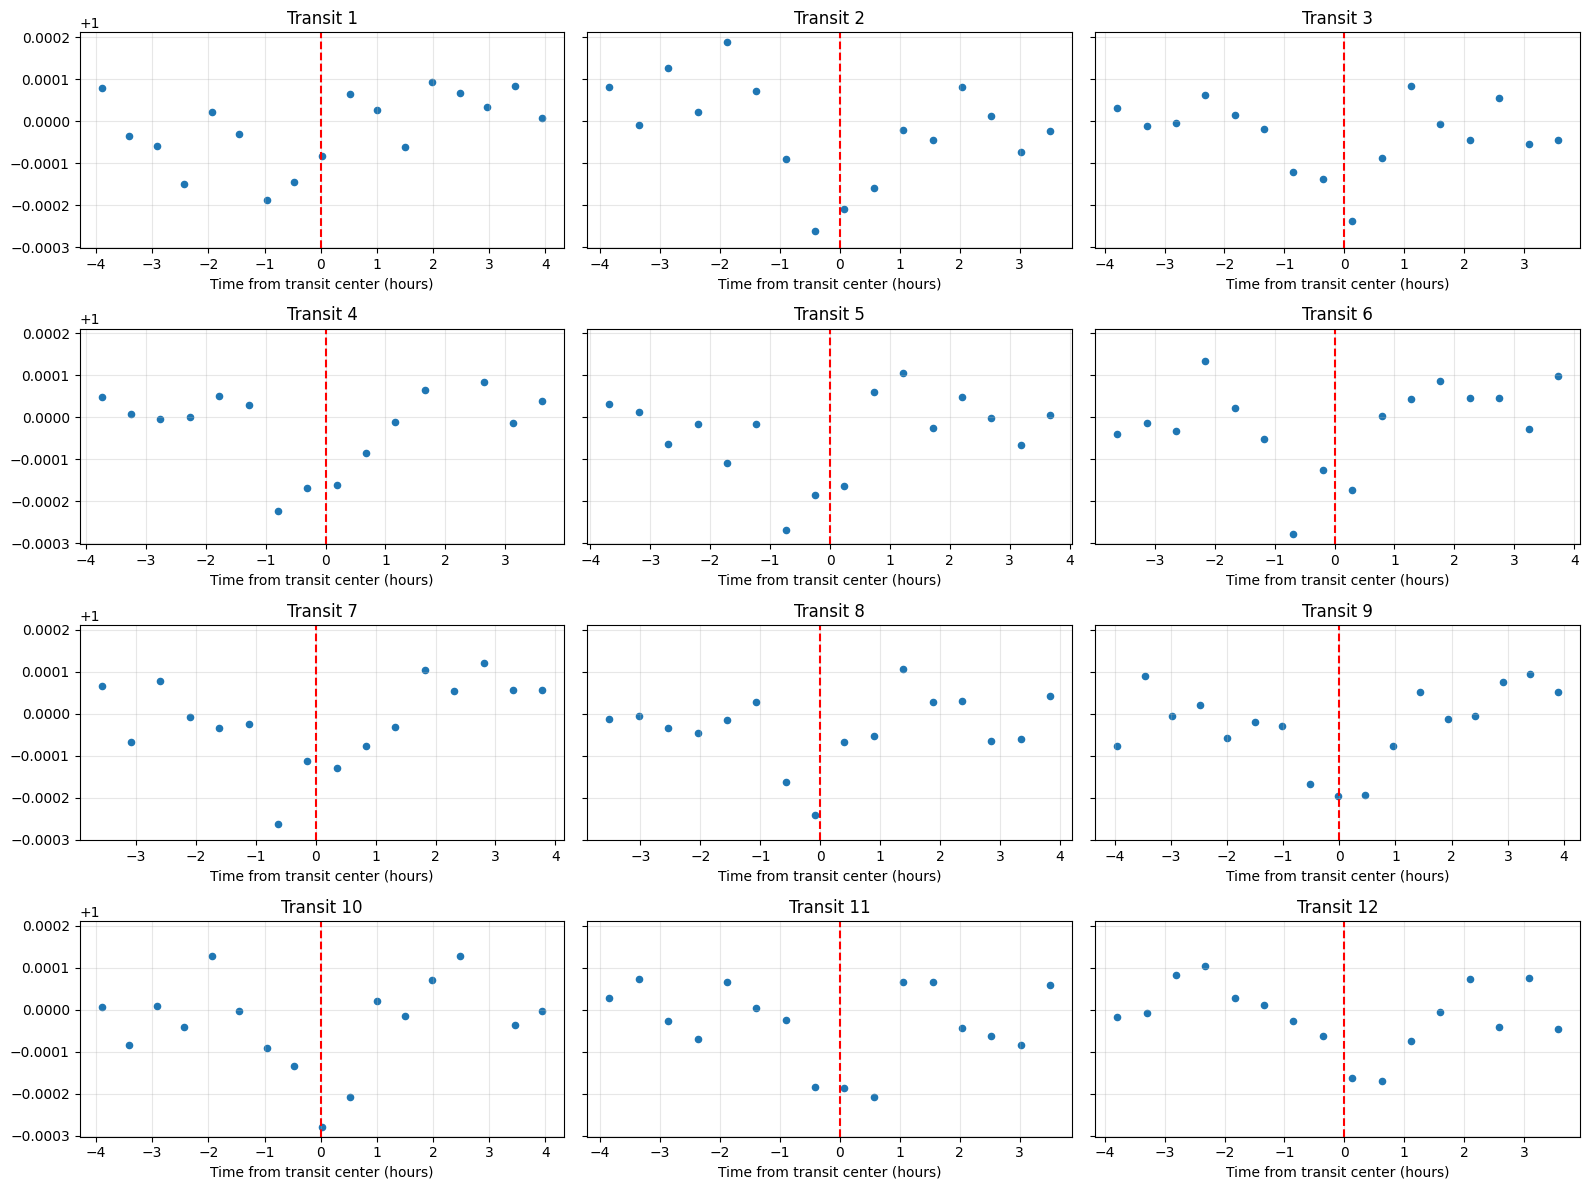

In [ ]:
transit_times = stats["transit_times"].to_value(u.day)

duration_days = best_duration.to_value(u.day)

fig, axes = plt.subplots(
    4, 3,
    figsize=(16, 12),
    sharey=True
)

axes = axes.flatten()

for i, transit_center in enumerate(transit_times):

    mask = (
        np.abs(time - transit_center)
        < 2 * duration_days
    )

    relative_time = (
        time[mask] - transit_center
    ) * 24

    axes[i].scatter(
        relative_time,
        flux[mask],
        s=20
    )

    axes[i].axvline(
        0,
        color="red",
        linestyle="--"
    )

    axes[i].set_title(
        f"Transit {i + 1}"
    )

    axes[i].set_xlabel("Time from transit center (hours)")
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Next experiment: compare the five strongest BLS peaks

In [ ]:
top_indices = np.argsort(
    periodogram.power
)[-5:][::-1]

print("Top 5 BLS candidates")
print("-" * 60)

for rank, index in enumerate(
    top_indices,
    start=1
):
    print(
        f"Rank {rank}: "
        f"Period = {periodogram.period[index].value:.6f} days, "
        f"Duration = {periodogram.duration[index].value * 24:.2f} hours, "
        f"Power = {periodogram.power[index]:.8e}"
    )

Top 5 BLS candidates
------------------------------------------------------------
Rank 1: Period = 0.835533 days, Duration = 2.00 hours, Power = 3.30306458e+02
Rank 2: Period = 0.835842 days, Duration = 2.00 hours, Power = 3.27399929e+02
Rank 3: Period = 0.836460 days, Duration = 2.00 hours, Power = 3.27399929e+02
Rank 4: Period = 0.835225 days, Duration = 2.00 hours, Power = 3.25579993e+02
Rank 5: Period = 0.836151 days, Duration = 2.00 hours, Power = 3.22421745e+02


### next research questions
Answer these in a new Markdown section in your notebook. Use your own understanding, not copied definitions.
1. Why is the highest BLS peak insufficient to confirm an exoplanet?
2. What physical information does transit depth provide?
3. Why do astronomers compare odd and even transit depths?
4. What is a period alias, and how can it affect BLS?
5. Why is the uncertainty in transit depth important?
6. What evidence would make a periodic transit candidate more trustworthy?

In [27]:
transit_results = []

for i, transit_center in enumerate(transit_times):

    # Define local transit region
    local_mask = (
        np.abs(time - transit_center)
        < 2 * duration_days
    )

    # Define approximate in-transit region
    in_mask = (
        np.abs(time - transit_center)
        < duration_days / 2
    ) & local_mask

    # Define approximate out-of-transit region
    out_mask = (
        np.abs(time - transit_center)
        >= duration_days / 2
    ) & local_mask

    local_flux = flux[local_mask]

    if np.any(in_mask) and np.any(out_mask):

        in_flux = np.median(flux[in_mask])
        out_flux = np.median(flux[out_mask])

        individual_depth = out_flux - in_flux

    else:
        individual_depth = np.nan

    transit_results.append({
        "Transit": i + 1,
        "Transit Time": transit_center,
        "Observations": len(local_flux),
        "Individual Depth": individual_depth
    })

transit_df = pd.DataFrame(transit_results)

display(transit_df)

,Transit,Transit Time,Observations,Individual Depth
0,1,120.701647,17,0.000135
1,2,121.537180,16,0.000201
2,3,122.372713,16,0.000124
3,4,123.208246,15,0.000196
4,5,124.043779,16,0.000166
5,6,124.879312,16,0.000181
6,7,125.714846,16,0.000176
7,8,126.550379,16,0.000106
8,9,127.385912,17,0.000176
9,10,128.221445,16,0.000173


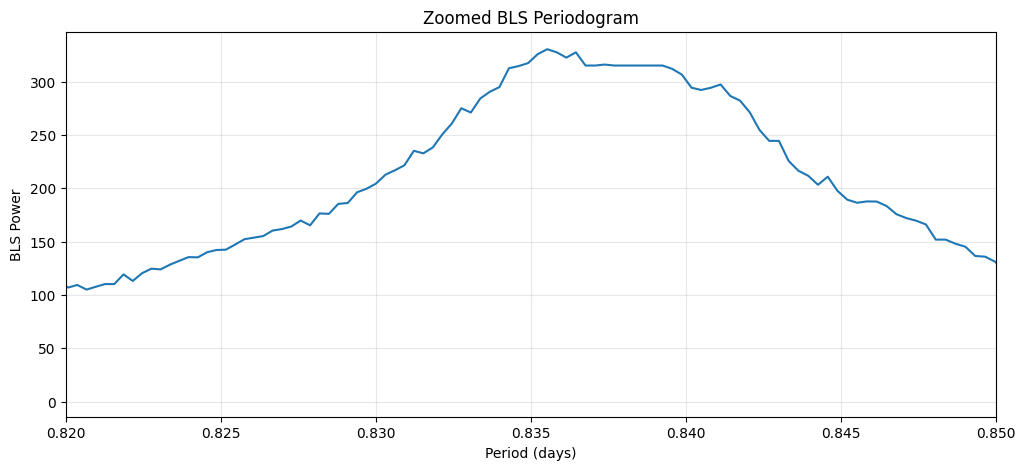

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    periodogram.period.to_value(u.day),
    periodogram.power
)

plt.xlim(
    0.82,
    0.85
)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("Zoomed BLS Periodogram")

plt.grid(alpha=0.3)
plt.show()

In [28]:
odd_depth, odd_err = stats["depth_odd"]
even_depth, even_err = stats["depth_even"]

depth_difference = odd_depth - even_depth

combined_error = np.sqrt(
    odd_err**2 + even_err**2
)

difference_significance = (
    abs(depth_difference) / combined_error
)

print("Odd transit depth:", odd_depth)
print("Even transit depth:", even_depth)

print("Depth difference:", depth_difference)

print(
    "Difference significance:",
    difference_significance
)

Odd transit depth: 0.00015897685793297978
Even transit depth: 0.00014755763273677225
Depth difference: 1.1419225196207528e-05
Difference significance: 0.9313169139474596


Research interpretation — Kepler-10 BLS candidate
The BLS algorithm identifies a periodic transit-like signal with a candidate period of approximately 0.835533 days. The odd and even transit depths are approximately 0.00015898 and 0.00014756, respectively. Their difference is approximately 0.93 combined standard deviations, which does not indicate a statistically significant odd-even depth discrepancy.

This result is consistent with a periodic transit signal, but it is insufficient to establish planetary nature. Further validation requires individual transit inspection, systematic-noise assessment, centroid analysis where available, and comparison with independent observations or published validation information.